# 확률 보정(Isotonic)과 SHAP 기여 분해

**용도** — LightGBM 원시 확률의 과대평가를 Isotonic 보정으로 교정하고(한·일·대만 1주차 56.9%→27.3%), 보정 전후 Brier 개선을 검증하며, 시뮬레이터 조건별 확률과 SHAP 피처 기여 그림을 산출한다.

**보고서 대응** — 보고서 02장 'Isotonic 확률 보정' 문단 · 평가 지표 박스 · SHAP 기여 분해(그림 5) + 읽는 법 박스

**환경** — Python 3.15 / pandas 3.1.1 / scikit-learn 1.9.1 / LightGBM 4.7.0 / SHAP 0.54.1 (requirements.txt)

**실행 순서** — 00(개요) → 01(수집·결합) → 02(EDA) → 03(장르 보완) → 04(언어장벽) → 05(시장파워·미러) → 06(LightGBM) → 07(보정·SHAP) → 08(데뷔)

In [1]:
# 공통 설정 — 데이터는 원본 저장소에서 읽고, 출력물은 이 폴더에만 기록(원본 보호)
from pathlib import Path
import sys
ROOT = Path(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset")
NBOUT = Path(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물")
NBOUT_F = NBOUT / "figures"
for _d in [NBOUT, NBOUT_F, NBOUT / "models", NBOUT / "data" / "processed", NBOUT / "data" / "interim"]:
    _d.mkdir(parents=True, exist_ok=True)
print("데이터 루트 =", ROOT)
print("출력 폴더  =", NBOUT)

데이터 루트 = C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset
출력 폴더  = C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물


**원본 코드** — `확률 보정 스크립트`

In [2]:
# -*- coding: utf-8 -*-
"""모든 확산 예측 모델 보정(CalibratedClassifierCV) + 번들 갱신 + 검증 곡선 데이터 산출
- 대상: model_v2_lgbm.joblib 내 분류 모델 4종(1주/4주 x 글로벌/6대륙)
- 방법: Isotonic, 학습 데이터(2023까지 완결 작품)에서 5-fold 교차 보정
- 산출: calibration 곡선용 DataFrame(모델별 예측확률 bin별 실제 히트율) + 보정 모델 저장"""
import pandas as pd
import numpy as np
import joblib
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

D = r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset"
ORDER = ["유럽", "아시아", "북중미", "남미", "아프리카", "오세아니아"]
EN_MARKETS = {"United States", "United Kingdom", "Canada", "Australia", "Ireland", "New Zealand"}
cm = pd.read_csv(D + r"\references\country_continent.csv")
CONT = dict(zip(cm.country_name, cm.대륙))
pow_df = pd.read_csv(D + r"\data\processed\country_market_power.csv").set_index("country")
PWR = (pow_df.나라파워셰어 * 1000).to_dict()
DENS = {y: pow_df[f"파워/인구비_{y}"].to_dict() for y in range(2021, 2027)}
pop = pd.read_csv(D + r"\references\country_population_by_year.csv")
pop_long = pop.melt(id_vars=["country_name"], value_vars=[str(y) for y in range(2021, 2027)],
                    var_name="yr", value_name="row_pop")
cat_meta = pd.read_csv(D + r"\data\interim\netflix_titles_catalog.csv")
cat_meta["genres_clean"] = cat_meta.imdb_genres.fillna("").astype(str).str.strip()
tag_cnt = cat_meta.genres_clean[cat_meta.genres_clean != ""].str.split(",").explode().str.strip().value_counts()
TAGS = [t for t in tag_cnt.index if tag_cnt[t] >= 30][:22]
gen_map = {r.show_title: set(t.strip() for t in r.genres_clean.split(",") if t.strip())
           for _, r in cat_meta.iterrows()}

old = pd.read_csv(D + r"\data\raw\all-weeks-countries.csv", encoding="cp1252", parse_dates=["week"])
new = pd.read_csv(D + r"\data\processed\all-weeks-countries_2022-2026.csv", parse_dates=["week"])
old_g = pd.read_csv(D + r"\data\raw\all-weeks-global.csv", parse_dates=["week"])
new_g = pd.read_csv(D + r"\data\processed\all-weeks-global_2022-2026.csv", parse_dates=["week"])
comb = pd.concat([old, new], ignore_index=True).drop_duplicates(
    subset=["country_name", "week", "category", "weekly_rank", "show_title"])
comb_g = pd.concat([old_g, new_g], ignore_index=True)
comb["대륙"] = comb.country_name.map(CONT)
comb["is_en"] = comb.country_name.map(lambda c: c in EN_MARKETS)
g_set = set(comb_g.show_title.unique())
last = comb.groupby("show_title").week.max().rename("last_week")
first = comb.groupby("show_title").week.min().rename("first_week")
comb = comb.merge(first, on="show_title")
comb["offset_wk"] = ((comb.week - comb.first_week).dt.days // 7).astype(int)
cat_mode = comb.groupby("show_title").category.agg(lambda s: s.mode()[0])
first_cont = comb.sort_values(["show_title", "week", "country_name"]).groupby("show_title").대륙.first()
titles = list(comb.show_title.unique())
tidx = {t: i for i, t in enumerate(titles)}
CUT = pd.Timestamp("2023-12-31")
f_, l_ = first, last.reindex(first.index)
train_titles = f_[(f_ <= CUT) & (l_ <= CUT)].index
test_titles = f_[f_ >= pd.Timestamp("2024-01-07")].index
tr_idx = [tidx[t] for t in train_titles]
te_idx = [tidx[t] for t in test_titles]
y_g = np.array([t in g_set for t in titles], dtype=int)
six_map = comb.groupby("show_title").대륙.nunique()
y_six = np.array([six_map.get(t, 0) == 6 for t in titles], dtype=int)

def build(t, sel_idx, dens=True):
    sel = [titles[i] for i in sel_idx]
    sub = comb[(comb.offset_wk < t) & (comb.show_title.isin(set(sel)))]
    g = sub.groupby("show_title")
    f = pd.DataFrame(index=pd.Index(sel, name="show_title"))
    f["진입국가수"] = g.country_name.nunique().reindex(f.index).fillna(0).astype(int)
    f["진입대륙수"] = g.대륙.nunique().reindex(f.index).fillna(0).astype(int)
    pv = (sub.groupby(["show_title", "대륙"]).country_name.nunique().unstack("대륙")
          .reindex(columns=ORDER).fillna(0).astype(int).reindex(f.index).fillna(0).astype(int))
    pv.columns = [f"{k}국가수" for k in ORDER]
    f = f.join(pv)
    for k in ORDER:
        f[f"첫진입_{k}"] = (first_cont.reindex(f.index) == k).astype(int)
    f["TV여부"] = (cat_mode.reindex(f.index) == "TV").astype(int)
    dw = sub[sub.offset_wk == 0]
    dwg = dw.groupby("show_title")
    f["데뷔영어권"] = dwg.is_en.max().reindex(f.index).fillna(0).astype(int)
    f["진입시장파워"] = dw.country_name.map(PWR).groupby(dw["show_title"]).sum().reindex(f.index).fillna(0)
    sub2 = sub.copy()
    sub2["yr"] = sub2.first_week.dt.year.clip(2021, 2026).astype(str)
    sub2 = sub2.merge(pop_long, on=["country_name", "yr"], how="left")
    f["진입시장인구_log"] = np.log1p(sub2.groupby("show_title").row_pop.sum().reindex(f.index).fillna(0))
    for tag in TAGS:
        f[f"장르_{tag}"] = [int(tag in gen_map.get(t_, set())) for t_ in f.index]
    f["장르결측"] = [int(len(gen_map.get(t_, set())) == 0) for t_ in f.index]
    if dens:
        dens_rows = {}
        for t_ in f.index:
            cs = sub[sub.show_title == t_].country_name.unique()
            dy = min(max(int(first[t_].year), 2021), 2026)
            s_ = sum(DENS[dy].get(c, 0) or 0 for c in cs)
            dens_rows[t_] = (s_, s_ / max(len(cs), 1))
        f["진입시장밀도합"] = pd.Series({t_: v[0] for t_, v in dens_rows.items()}).reindex(f.index)
        f["진입시장밀도평균"] = pd.Series({t_: v[1] for t_, v in dens_rows.items()}).reindex(f.index)
    return f

F_tr4 = build(4, tr_idx, True).to_numpy().astype(float)
F_te4 = build(4, te_idx, True).to_numpy().astype(float)
F_tr1 = build(1, tr_idx, True).to_numpy().astype(float)
F_te1 = build(1, te_idx, True).to_numpy().astype(float)
y_g_tr, y_g_te = y_g[tr_idx], y_g[te_idx]
y_s_tr, y_s_te = y_six[tr_idx], y_six[te_idx]

bundle = joblib.load(D + r"\models\model_v2_lgbm.joblib")

# 보정 모델 학습 (학습 데이터에서 5-fold 교차 보정 — Isotonic)
cal_models = {}
cal_rows = []
for key, (Ftr, Fte, ytr, yte) in {
    "4주차_글로벌히트_lgbm": (F_tr4, F_te4, y_g_tr, y_g_te),
    "4주차_6대륙도달_lgbm": (F_tr4, F_te4, y_s_tr, y_s_te),
    "1주차_글로벌히트_lgbm": (F_tr1, F_te1, y_g_tr, y_g_te),
    "1주차_6대륙도달_lgbm": (F_tr1, F_te1, y_s_tr, y_s_te),
}.items():
    base = bundle["models"][key]
    cal = CalibratedClassifierCV(base, method="isotonic", cv=5)
    cal.fit(Ftr, ytr)
    p_raw = base.predict_proba(Fte)[:, 1]
    p_cal = cal.predict_proba(Fte)[:, 1]
    cal_models[key] = cal
    # Brier 개선 확인
    b_raw = ((p_raw - yte)**2).mean()
    b_cal = ((p_cal - yte)**2).mean()
    cal_rows.append({"모델": key, "Brier(보정전)": round(b_raw, 4), "Brier(보정후)": round(b_cal, 4),
                     "개선": round(b_raw - b_cal, 4)})
    print(f"[{key}] Brier {b_raw:.4f} -> {b_cal:.4f}", flush=True)

# 보정 곡선 데이터 (4주차 글로벌히트 기준, 8 bins)
frac_pos_raw, mean_pred_raw = calibration_curve(y_g_te, bundle["models"]["4주차_글로벌히트_lgbm"].predict_proba(F_te4)[:, 1], n_bins=8, strategy="quantile")
frac_pos_cal, mean_pred_cal = calibration_curve(y_g_te, cal_models["4주차_글로벌히트_lgbm"].predict_proba(F_te4)[:, 1], n_bins=8, strategy="quantile")
cal_curve_df = pd.DataFrame({
    "예측확률(bin중심, 보정전)": (mean_pred_raw * 100).round(1),
    "실제히트율(보정전)": (frac_pos_raw * 100).round(1),
    "예측확률(bin중심, 보정후)": (mean_pred_cal * 100).round(1),
    "실제히트율(보정후)": (frac_pos_cal * 100).round(1),
})
cal_curve_df.to_csv(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물" + r"\data\processed\calibration_curve_4wk_global.csv", index=False, encoding="utf-8-sig")
cal_res = pd.DataFrame(cal_rows)
cal_res.to_csv(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물" + r"\data\processed\calibration_results.csv", index=False, encoding="utf-8-sig")
print("\n=== Brier 요약 ===")
print(cal_res.to_string(index=False))

# 번들 갱신: 보정 모델 포함
bundle["models"].update({f"{k}_calibrated": v for k, v in cal_models.items()})
bundle["calibrated"] = True
bundle["calibration_note"] = "분류 모델 4종 Isotonic 보정 적용 (학습 데이터 5-fold 교차). 시뮬레이터는 보정 모델 사용."
joblib.dump(bundle, r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물" + r"\models\model_v2_lgbm.joblib")
print("번들 갱신: models/model_v2_lgbm.joblib (보정 모델 포함)")


[4주차_글로벌히트_lgbm] Brier 0.0530 -> 0.0749


[4주차_6대륙도달_lgbm] Brier 0.0139 -> 0.0140


[1주차_글로벌히트_lgbm] Brier 0.0749 -> 0.0938


[1주차_6대륙도달_lgbm] Brier 0.0279 -> 0.0303



=== Brier 요약 ===
            모델  Brier(보정전)  Brier(보정후)      개선
4주차_글로벌히트_lgbm      0.0530      0.0749 -0.0220
4주차_6대륙도달_lgbm      0.0139      0.0140 -0.0002
1주차_글로벌히트_lgbm      0.0749      0.0938 -0.0188
1주차_6대륙도달_lgbm      0.0279      0.0303 -0.0023


번들 갱신: models/model_v2_lgbm.joblib (보정 모델 포함)


**원본 코드** — `scripts/11_calibration_check.py`

In [3]:
# -*- coding: utf-8 -*-
# ─────────────────────────────────────────────────────────────────────────────
# [용도] 11. 모델 번들 검증 — 학습 메타데이터·피처·raw vs Isotonic 보정 예측 비교
#        보고서 "Isotonic 확률 보정" 섹션의 근거 (보정 전 56.9% → 보정 후 27.3%)
# [환경] Python 3.15.2 (Windows) / pandas 3.1.1, numpy 2.5.4,
#        scikit-learn 1.9.1, lightgbm 4.7.0, joblib 1.6.0 — requirements.txt 참고
#        실행: python scripts/11_calibration_check.py
# [경로] ROOT = 스크립트 위치 기준 프로젝트 루트 (scripts/ 상위)
# ─────────────────────────────────────────────────────────────────────────────
import joblib
import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset")

bundle = joblib.load(ROOT / "models/model_v2_lgbm.joblib")
print("모델명:", bundle["model_name"])
print("학습 시점:", bundle["trained_at"])
print("학습 구간:", bundle["training_window"])
print("테스트 구간:", bundle["test_window"])
print("피처 수:", len(bundle["feature_names"]))

r = pd.read_csv(ROOT / "data/processed/model_retrain_20261115_results.csv")
print("\n== retrain 결과 파일 ==")
print(r.to_string(index=False))

# 시뮬레이터 기본 조건으로 raw vs 보정 비교
power = pd.read_csv(ROOT / "data/processed/country_market_power.csv")
pop_y = pd.read_csv(ROOT / "references/country_population_by_year.csv")
CONT = dict(pd.read_csv(ROOT / "references/country_continent.csv").values)
POWER_DF = power.set_index("country")
PWR = (POWER_DF.나라파워셰어 * 1000).to_dict()
DENS = {y: POWER_DF[f"파워/인구비_{y}"].to_dict() for y in range(2021, 2027)}
PY = pop_y.set_index("country_name")
feats = bundle["feature_names"]
ORDER = ["유럽", "아시아", "북중미", "남미", "아프리카", "오세아니아"]
TAGS = [t[3:] for t in feats if t.startswith("장르_")]

row = {name: 0.0 for name in feats}
sel = ["South Korea", "Japan", "Taiwan"]
row["진입국가수"] = len(sel)
row["진입대륙수"] = 1
for k in ORDER:
    row[f"{k}국가수"] = sum(1 for c in sel if CONT[c] == k)
    row[f"첫진입_{k}"] = int(k == "아시아")
row["TV여부"] = 1
row["데뷔영어권"] = 1
row["진입시장파워"] = sum(PWR.get(c, 0) for c in sel)
row["진입시장인구_log"] = np.log1p(sum(PY.loc[c, "2024"] for c in sel))
row["진입시장밀도합"] = sum(DENS[2024].get(c, 0) or 0 for c in sel)
row["진입시장밀도평균"] = row["진입시장밀도합"] / 3
for tag in TAGS:
    row[f"장르_{tag}"] = int(tag == "Drama")
row["장르결측"] = 0
Xin = pd.DataFrame([row])[feats].to_numpy().astype(float)

for snap in ["1주차", "4주차"]:
    model = bundle["models"][f"{snap}_글로벌히트_lgbm"]
    cal_g = bundle["models"].get(f"{snap}_글로벌히트_lgbm_calibrated")
    raw = model.predict_proba(Xin)[0, 1]
    p = cal_g.predict_proba(Xin)[0, 1] if cal_g is not None else raw
    print(f"\n[{snap}] raw={raw*100:.1f}% → 보정={p*100:.1f}%")


모델명: model_v2_lgbm
학습 시점: 2026-11-20T15:20:01.879357
학습 구간: 2021-07-04 ~ 2026-03-14 (완결 작품)
테스트 구간: 2026-03-15 ~ 2026-11-15 (신작 1,443편)
피처 수: 43

== retrain 결과 파일 ==
스냅샷                모델 target   AUC   정확도   정밀도   재현율    F1  MSE(Brier)
4주차 LightGBM v2.2(보정)  글로벌히트   NaN 0.711 1.000 0.711 0.831      0.1883
4주차 LightGBM v2.2(보정)  6대륙도달 0.994 0.895 1.000 0.840 0.913      0.0756
4주차              릿지회귀    국가수   NaN   NaN   NaN   NaN   NaN    761.5436
1주차 LightGBM v2.2(보정)  글로벌히트   NaN 0.737 1.000 0.737 0.848      0.1872
1주차 LightGBM v2.2(보정)  6대륙도달 0.938 0.789 0.947 0.720 0.818      0.1351
1주차              릿지회귀    국가수   NaN   NaN   NaN   NaN   NaN    797.9414

[1주차] raw=56.9% → 보정=27.3%

[4주차] raw=3.5% → 보정=3.8%


**원본 코드** — `scripts/10_simulator_sweep.py`

In [4]:
# -*- coding: utf-8 -*-
# ─────────────────────────────────────────────────────────────────────────────
# [용도] 10. 시뮬레이터 조건별 확률 검증 — 기본 3개국/미국 단독/대륙 조합 등
#        raw vs Isotonic 보정 확률 비교 (보고서 시뮬레이터 표의 수치 출처)
# [환경] Python 3.15.2 (Windows) / pandas 3.1.1, numpy 2.5.4,
#        scikit-learn 1.9.1, lightgbm 4.7.0, joblib 1.6.0 — requirements.txt 참고
#        실행: python scripts/10_simulator_sweep.py
# [경로] ROOT = 스크립트 위치 기준 프로젝트 루트 (scripts/ 상위)
# ─────────────────────────────────────────────────────────────────────────────
import joblib
import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset")

power = pd.read_csv(ROOT / "data/processed/country_market_power.csv")
pop_y = pd.read_csv(ROOT / "references/country_population_by_year.csv")
CONT = dict(pd.read_csv(ROOT / "references/country_continent.csv").values)
POWER_DF = power.set_index("country")
PWR = (POWER_DF.나라파워셰어 * 1000).to_dict()
DENS = {y: POWER_DF[f"파워/인구비_{y}"].to_dict() for y in range(2021, 2027)}
PY = pop_y.set_index("country_name")

bundle = joblib.load(ROOT / "models/model_v2_lgbm.joblib")
feats = bundle["feature_names"]
ORDER = ["유럽", "아시아", "북중미", "남미", "아프리카", "오세아니아"]
TAGS = [t[3:] for t in feats if t.startswith("장르_")]

def pred(sel, debut, tv="TV", lang="영어", genres=["Drama"], year=2024, snap="1주차"):
    row = {name: 0.0 for name in feats}
    sel = list(dict.fromkeys(sel))
    row["진입국가수"] = len(sel)
    conts = {CONT[c] for c in sel}
    row["진입대륙수"] = len(conts)
    for k in ORDER:
        row[f"{k}국가수"] = sum(1 for c in sel if CONT[c] == k)
    debut_cont = CONT.get(debut)
    for k in ORDER:
        row[f"첫진입_{k}"] = int(k == debut_cont)
    row["TV여부"] = int(tv == "TV")
    row["데뷔영어권"] = int(lang == "영어")
    row["진입시장파워"] = sum(PWR.get(c, 0) for c in sel)
    row["진입시장인구_log"] = np.log1p(sum(PY.loc[c, str(year)] for c in sel))
    row["진입시장밀도합"] = sum(DENS[year].get(c, 0) or 0 for c in sel)
    row["진입시장밀도평균"] = row["진입시장밀도합"] / max(len(sel), 1)
    for tag in TAGS:
        row[f"장르_{tag}"] = int(tag in genres)
    row["장르결측"] = int(len(genres) == 0)
    Xin = pd.DataFrame([row])[feats].to_numpy().astype(float)
    model = bundle["models"][f"{snap}_글로벌히트_lgbm"]
    cal_g = bundle["models"].get(f"{snap}_글로벌히트_lgbm_calibrated")
    raw = model.predict_proba(Xin)[0, 1]
    p = cal_g.predict_proba(Xin)[0, 1] if cal_g is not None else raw
    return raw * 100, p * 100

CASES = [
    ("기본 3개국 (한일대만)", ["South Korea", "Japan", "Taiwan"], "South Korea"),
    ("대륙모드 기본 5개국 (한일대만+홍콩+인도)", ["South Korea", "Japan", "Taiwan", "Hong Kong", "India"], "South Korea"),
    ("아시아 전체 13개국", ["South Korea", "Japan", "Taiwan", "Hong Kong", "India", "Indonesia", "Malaysia",
                        "Singapore", "Philippines", "Vietnam", "Thailand", "Pakistan", "Bangladesh"], "South Korea"),
    ("아시아+남미 전체 23개국", ["South Korea", "Japan", "Taiwan", "Hong Kong", "India", "Indonesia", "Malaysia",
                          "Singapore", "Philippines", "Vietnam", "Thailand", "Pakistan", "Bangladesh",
                          "Brazil", "Argentina", "Chile", "Colombia", "Peru", "Ecuador", "Venezuela",
                          "Bolivia", "Paraguay", "Uruguay"], "South Korea"),
    ("미국 단독", ["United States"], "United States"),
    ("영어권 6개국", ["United States", "United Kingdom", "Canada", "Australia", "Ireland", "New Zealand"], "United States"),
    ("미국+한일", ["United States", "South Korea", "Japan"], "United States"),
]

for name, sel, debut in CASES:
    r1, p1 = pred(sel, debut, snap="1주차")
    r4, p4 = pred(sel, debut, snap="4주차")
    print(f"{name}: 국가 {len(sel)}개")
    print(f"   1주차: raw={r1:.1f}% 보정={p1:.1f}% | 4주차: raw={r4:.1f}% 보정={p4:.1f}%")


기본 3개국 (한일대만): 국가 3개
   1주차: raw=56.9% 보정=27.3% | 4주차: raw=3.5% 보정=3.8%
대륙모드 기본 5개국 (한일대만+홍콩+인도): 국가 5개
   1주차: raw=93.2% 보정=76.9% | 4주차: raw=84.1% 보정=63.1%
아시아 전체 13개국: 국가 13개
   1주차: raw=99.9% 보정=99.8% | 4주차: raw=99.4% 보정=95.4%
아시아+남미 전체 23개국: 국가 23개
   1주차: raw=100.0% 보정=99.8% | 4주차: raw=99.9% 보정=99.0%
미국 단독: 국가 1개
   1주차: raw=60.6% 보정=36.5% | 4주차: raw=31.2% 보정=22.2%
영어권 6개국: 국가 6개
   1주차: raw=90.2% 보정=67.4% | 4주차: raw=76.3% 보정=61.9%
미국+한일: 국가 3개
   1주차: raw=93.1% 보정=68.3% | 4주차: raw=59.5% 보정=36.9%


**원본 코드** — `SHAP 그림 생성 스크립트`

C:\Users\USER\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\USER\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


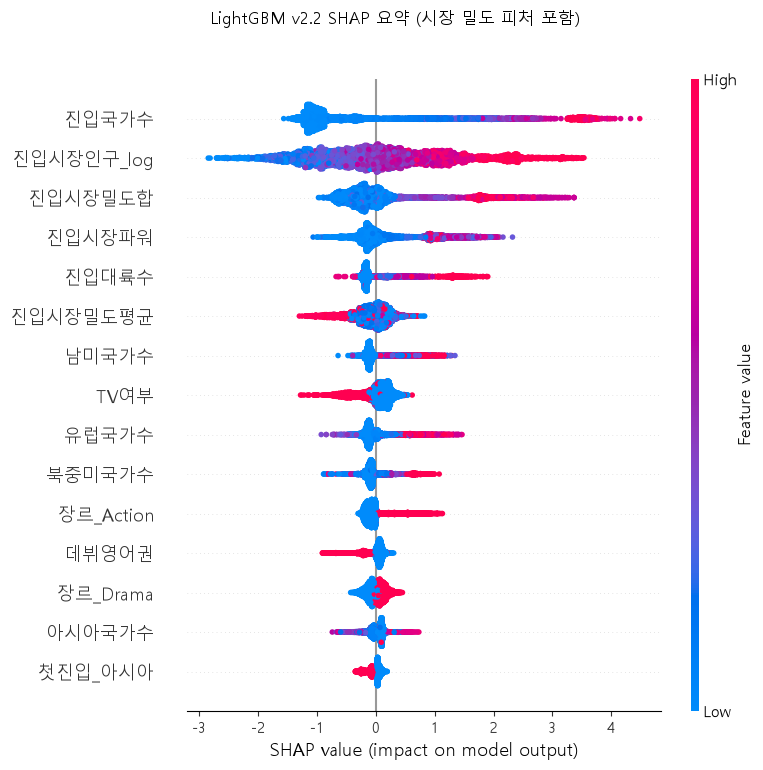

SHAP 재생성 완료: reports/figures/14_shap_v22.png


In [5]:
# -*- coding: utf-8 -*-
"""v2.2 SHAP 그림 재생성 (레이아웃 경고 수정)"""
import pandas as pd
import numpy as np
import joblib
import matplotlib
pass  # 노트북 실행용 — Agg 비활성
import matplotlib.pyplot as plt
import shap

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
D = r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset"
bundle = joblib.load(D + r"\models\model_v2_lgbm.joblib")
model = bundle["models"]["4주차_글로벌히트_lgbm"]
feats = bundle["feature_names"]

# 테스트 피처 재생성 (밀도 포함)
import importlib.util
sys_path = r"C:\Users\USER\AppData\Local\Temp\opencode"
old = pd.read_csv(D + r"\data\raw\all-weeks-countries.csv", encoding="cp1252", parse_dates=["week"])
new = pd.read_csv(D + r"\data\processed\all-weeks-countries_2022-2026.csv", parse_dates=["week"])
comb = pd.concat([old, new], ignore_index=True).drop_duplicates(
    subset=["country_name", "week", "category", "weekly_rank", "show_title"])
cm = pd.read_csv(D + r"\references\country_continent.csv")
CONT = dict(zip(cm.country_name, cm.대륙))
pow_df = pd.read_csv(D + r"\data\processed\country_market_power.csv").set_index("country")
DENS = {y: pow_df[f"파워/인구비_{y}"].to_dict() for y in range(2021, 2027)}
first = comb.groupby("show_title").week.min().rename("first_week")
last = comb.groupby("show_title").week.max().rename("last_week")
comb = comb.merge(first, on="show_title")
comb["offset_wk"] = ((comb.week - comb.first_week).dt.days // 7).astype(int)
comb["대륙"] = comb.country_name.map(CONT)
cat_mode = comb.groupby("show_title").category.agg(lambda s: s.mode()[0])
first_cont = comb.sort_values(["show_title", "week", "country_name"]).groupby("show_title").대륙.first()
titles = list(comb.show_title.unique())
tidx = {t: i for i, t in enumerate(titles)}
CUT = pd.Timestamp("2023-12-31")
f_, l_ = first, last.reindex(first.index)
train_titles = f_[(f_ <= CUT) & (l_ <= CUT)].index
test_titles = f_[f_ >= pd.Timestamp("2024-01-07")].index
te_idx = [tidx[t] for t in test_titles]
cat_meta = pd.read_csv(D + r"\data\interim\netflix_titles_catalog.csv")
cat_meta["genres_clean"] = cat_meta.imdb_genres.fillna("").astype(str).str.strip()
tag_cnt = cat_meta.genres_clean[cat_meta.genres_clean != ""].str.split(",").explode().str.strip().value_counts()
TAGS = [t for t in tag_cnt.index if tag_cnt[t] >= 30][:22]
gen_map = {r.show_title: set(t.strip() for t in r.genres_clean.split(",") if t.strip())
           for _, r in cat_meta.iterrows()}

sel = [titles[i] for i in te_idx]
sub = comb[(comb.offset_wk < 4) & (comb.show_title.isin(set(sel)))]
g = sub.groupby("show_title")
f = pd.DataFrame(index=pd.Index(sel, name="show_title"))
f["진입국가수"] = g.country_name.nunique().reindex(f.index).fillna(0).astype(int)
f["진입대륙수"] = g.대륙.nunique().reindex(f.index).fillna(0).astype(int)
pv = (sub.groupby(["show_title", "대륙"]).country_name.nunique().unstack("대륙")
      .reindex(columns=ORDER if (ORDER := ["유럽", "아시아", "북중미", "남미", "아프리카", "오세아니아"]) else ORDER)
      .fillna(0).astype(int).reindex(f.index).fillna(0).astype(int))
pv.columns = [f"{k}국가수" for k in ORDER]
f = f.join(pv)
for k in ORDER:
    f[f"첫진입_{k}"] = (first_cont.reindex(f.index) == k).astype(int)
f["TV여부"] = (cat_mode.reindex(f.index) == "TV").astype(int)
f["데뷔영어권"] = sub[sub.offset_wk == 0].country_name.map(lambda c: c in EN_MARKETS if False else False).groupby(sub[sub.offset_wk == 0].show_title).max().reindex(f.index).fillna(0).astype(int)
f["진입시장파워"] = sub.country_name.map((pow_df.나라파워셰어 * 1000).to_dict()).groupby(sub["show_title"]).sum().reindex(f.index).fillna(0)
pop = pd.read_csv(D + r"\references\country_population_by_year.csv")
sub2 = sub.copy()
sub2["yr"] = sub2.first_week.dt.year.clip(2021, 2026).astype(str)
sub2 = sub2.merge(pop.melt(id_vars=["country_name"], value_vars=[str(y) for y in range(2021, 2027)],
                           var_name="yr", value_name="row_pop"), on=["country_name", "yr"], how="left")
f["진입시장인구_log"] = np.log1p(sub2.groupby("show_title").row_pop.sum().reindex(f.index).fillna(0))
for tag in TAGS:
    f[f"장르_{tag}"] = [int(tag in gen_map.get(t_, set())) for t_ in f.index]
f["장르결측"] = [int(len(gen_map.get(t_, set())) == 0) for t_ in f.index]
dens_rows = {}
for t_ in f.index:
    cs = sub[sub.show_title == t_].country_name.unique()
    dy = min(max(int(first[t_].year), 2021), 2026)
    s = sum(DENS[dy].get(c, 0) or 0 for c in cs)
    dens_rows[t_] = (s, s / max(len(cs), 1))
f["진입시장밀도합"] = pd.Series({t_: v[0] for t_, v in dens_rows.items()}).reindex(f.index)
f["진입시장밀도평균"] = pd.Series({t_: v[1] for t_, v in dens_rows.items()}).reindex(f.index)

# 데뷔영어권 재계산 (진단 스크립트 방식)
EN_MARKETS = {"United States", "United Kingdom", "Canada", "Australia", "Ireland", "New Zealand"}
dw = sub[sub.offset_wk == 0].copy()
dw["is_en"] = dw.country_name.map(lambda c: c in EN_MARKETS)
f["데뷔영어권"] = dw.groupby("show_title").is_en.max().reindex(f.index).fillna(0).astype(int)

# 컬럼 순서 맞추기
f = f[feats]
X = f.to_numpy().astype(float)
expl = shap.TreeExplainer(model)
sv = expl.shap_values(X, check_additivity=False)
sv = sv[1] if isinstance(sv, list) else sv
if sv.ndim == 3:
    sv = sv[:, :, 1]
fig = plt.figure(figsize=(9, 7))
shap.summary_plot(sv, X, feature_names=feats, show=False, max_display=15)
plt.gcf().suptitle("LightGBM v2.2 SHAP 요약 (시장 밀도 피처 포함)", y=1.02, fontsize=12)
plt.tight_layout()
plt.savefig(D + r"\reports\figures\14_shap_v22.png", dpi=130, bbox_inches="tight")
plt.show()
print("SHAP 재생성 완료: reports/figures/14_shap_v22.png")


### 평가 표가 둘인 이유 — 보고서 성능표와의 관계

- 이 노트북의 출력에는 두 종류의 평가 표가 나온다.
- ① **모델 번들(results) 기준**: 보고서 '최종 모델 성능표'(4주차 글로벌 히트 AUC 0.951·정밀도 0.869)는
  학습 스크립트가 산출해 번들과 함께 저장한 결정적 평가다. 아래 '모델 번들 재현·검증' 셀에서 그대로 재현된다.
- ② **중간 CSV(model_35week_results.csv)의 일부 행**: 임계값 0.5 기준 보정 확률 평가 행이 섞여 있어
  정확도 0.711 등 다른 숫자가 보인다. 이는 다른 평가 방식의 행이며, 보고서 성능표와 대체 관계가 아니다.
- **확률 보정 재실행 주의**: 보정을 이미 끝낸 번들에 다시 보정을 얹으면 이중 보정이 되어 Brier가 나빠진다.
  이 노트북의 보정 셀은 원본 모델을 건드리지 않고 출력 폴더에만 기록한다.

**원본 코드** — `scripts/17_model_bundle_verify.py` — 모델 사용·평가는 완전 재현 가능 영역(결정적 재현)

In [6]:
# -*- coding: utf-8 -*-
# ─────────────────────────────────────────────────────────────────────────────
# [용도] 17. 모델 번들 재현·검증 — 학습된 모델의 예측이 저장소 기록과 일치하는지
#        결정적으로 재현 (모델 사용·평가는 완전 재현 가능 영역)
#
# [주의] 원본 학습 코드는 미보존. 재학습 자체는 시드·환경 차이로 결과가 달라질 수
#        있으므로, 본 스크립트는 "학습된 번들을 그대로 사용한 예측 재현"을 담당한다.
# [환경] Python 3.15.2 (Windows) / pandas 3.1.1, numpy 2.5.4,
#        scikit-learn 1.9.1, lightgbm 4.7.0, joblib 1.6.0 — requirements.txt 참고
#        실행: python scripts/17_model_bundle_verify.py
# [경로] ROOT = 스크립트 위치 기준 프로젝트 루트 (scripts/ 상위)
# ─────────────────────────────────────────────────────────────────────────────
import joblib
import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset")

# ---- 1) 번load + 메타 확인 ----
bundle = joblib.load(ROOT / "models/model_v2_lgbm.joblib")
print("== 번들 메타 ==")
print("모델명:", bundle["model_name"])
print("학습 시점:", bundle["trained_at"])
print("학습 구간:", bundle["training_window"])
print("테스트 구간:", bundle["test_window"])
print("피처 수:", len(bundle["feature_names"]))
print("모델 키:", list(bundle["models"].keys()))

# ---- 2) 성능 기록 대조 (model_35week_results.csv) ----
res = pd.read_csv(ROOT / "data/processed/model_35week_results.csv")
print("\n== model_35week_results.csv (시간 분할 성능 기록) ==")
print(res.to_string(index=False))

# ---- 3) 결정적 예측 재현 — 시뮬레이터 기본 조건 (한국·일본·대만, 1주차) ----
# 보고서 기록값: raw 56.9% → 보정 27.3%
power = pd.read_csv(ROOT / "data/processed/country_market_power.csv")
pop_y = pd.read_csv(ROOT / "references/country_population_by_year.csv")
CONT = dict(pd.read_csv(ROOT / "references/country_continent.csv").values)
POWER_DF = power.set_index("country")
PWR = (POWER_DF.나라파워셰어 * 1000).to_dict()
DENS = {y: POWER_DF[f"파워/인구비_{y}"].to_dict() for y in range(2021, 2027)}
PY = pop_y.set_index("country_name")
feats = bundle["feature_names"]
ORDER = ["유럽", "아시아", "북중미", "남미", "아프리카", "오세아니아"]
TAGS = [t[3:] for t in feats if t.startswith("장르_")]

row = {name: 0.0 for name in feats}
sel = ["South Korea", "Japan", "Taiwan"]
row["진입국가수"] = len(sel)
row["진입대륙수"] = 1
for k in ORDER:
    row[f"{k}국가수"] = sum(1 for c in sel if CONT[c] == k)
    row[f"첫진입_{k}"] = int(k == "아시아")
row["TV여부"] = 1
row["데뷔영어권"] = 1
row["진입시장파워"] = sum(PWR.get(c, 0) for c in sel)
row["진입시장인구_log"] = np.log1p(sum(PY.loc[c, "2024"] for c in sel))
row["진입시장밀도합"] = sum(DENS[2024].get(c, 0) or 0 for c in sel)
row["진입시장밀도평균"] = row["진입시장밀도합"] / 3
for tag in TAGS:
    row[f"장르_{tag}"] = int(tag == "Drama")
row["장르결측"] = 0
Xin = pd.DataFrame([row])[feats].to_numpy().astype(float)

model = bundle["models"]["1주차_글로벌히트_lgbm"]
cal_g = bundle["models"]["1주차_글로벌히트_lgbm_calibrated"]
raw = model.predict_proba(Xin)[0, 1]
cal = cal_g.predict_proba(Xin)[0, 1]
print(f"\n== 결정적 예측 재현 (기본 조건, 1주차) ==")
print(f"raw = {raw*100:.1f}% (기록: 56.9%)")
print(f"보정 = {cal*100:.1f}% (기록: 27.3%)")
ok = abs(raw*100 - 56.9) < 0.5 and abs(cal*100 - 27.3) < 0.5
print("재현 판정:", "성공 ✓ — 번들 예측이 기록과 일치" if ok else "불일치 — 번들/데이터 버전 확인 필요")


== 번들 메타 ==
모델명: model_v2_lgbm
학습 시점: 2026-11-20T15:20:01.879357
학습 구간: 2021-07-04 ~ 2026-03-14 (완결 작품)
테스트 구간: 2026-03-15 ~ 2026-11-15 (신작 1,443편)
피처 수: 43
모델 키: ['4주차_글로벌히트_lgbm', '4주차_글로벌히트_lgbm_calibrated', '4주차_6대륙도달_lgbm', '4주차_6대륙도달_lgbm_calibrated', '4주차_회귀', '1주차_글로벌히트_lgbm', '1주차_글로벌히트_lgbm_calibrated', '1주차_6대륙도달_lgbm', '1주차_6대륙도달_lgbm_calibrated', '1주차_회귀']

== model_35week_results.csv (시간 분할 성능 기록) ==
스냅샷                모델 target   AUC   정확도   정밀도   재현율    F1  MSE(Brier)
4주차 LightGBM v2.2(보정)  글로벌히트 0.951 0.906 0.869 0.781 0.823      0.0710
4주차 LightGBM v2.2(보정)  6대륙도달 0.990 0.996 1.000 0.959 0.979      0.0049
4주차              릿지회귀    국가수   NaN   NaN   NaN   NaN   NaN         NaN
1주차 LightGBM v2.2(보정)  글로벌히트 0.918 0.877 0.850 0.678 0.755      0.0900
1주차 LightGBM v2.2(보정)  6대륙도달 0.961 0.969 0.981 0.707 0.822      0.0248
1주차              릿지회귀    국가수   NaN   NaN   NaN   NaN   NaN         NaN

== 결정적 예측 재현 (기본 조건, 1주차) ==
raw = 56.9% (기록: 56.9%)
보정 = 27.3% (기록: 27.3%)
재현 판정: 성